# Etapa 3 — Análise Exploratória dos Dados (EDA)

Análise exploratória do dataset construído na Etapa 2, com **96.470 pedidos entregues** e **28 colunas**.

Objetivos:
- **Distribuição das variáveis:** histogramas e estatísticas descritivas para entender a forma das distribuições.
- **Identificação de outliers:** boxplots e método IQR para evidenciar valores atípicos.
- **Matriz de correlações:** heatmap e bar chart para verificar a relação linear entre as variáveis.
- **Estatísticas descritivas:** tabela com médias, medianas, desvios padrão, percentis, assimetria, curtose e nulos.
- **Mapas geográficos:** análise espacial através dos valores de latitude e longitude, incluindo vetores de entrega e comparação entre estados.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
from app.features import (
    COLUNAS_ASSIMETRICAS,
    COLUNAS_BINARIAS,
    COLUNAS_CATEGORICAS,
    COLUNAS_NUMERICAS,
    COLUNAS_TARGET_ENCODING,
    carregar_tabelas,
    construir_dataset,
)

DATA_DIR = RAIZ / 'data' / 'olist'

pd.set_option('display.float_format', '{:.2f}'.format)
plt.rcParams.update({'figure.max_open_warning': 0})

In [2]:
# Carregar tabelas brutas e construir o dataset.
tabelas = carregar_tabelas(DATA_DIR)
df = construir_dataset(tabelas)

print(f'Dataset: {len(df):,} pedidos | {df.shape[1]} colunas')
print(f'Colunas: {list(df.columns)}')
df.head(3)

Dataset: 96,470 pedidos | 28 colunas
Colunas: ['order_id', 'order_purchase_timestamp', 'y', 'prazo_estimado', 'mes', 'n_vendedores', 'frete_total', 'preco_total', 'peso_total_g', 'volume_total_cm3', 'dist_km', 'n_itens', 'customer_lat', 'customer_lng', 'seller_lat', 'seller_lng', 'mes_sin', 'mes_cos', 'dia_semana', 'hora', 'mesmo_estado', 'varios_vendedores', 'customer_state', 'seller_state', 'categoria', 'coord_cliente_imputada', 'coord_vendedor_imputada', 'coord_imputada']


,order_id,order_purchase_timestamp,y,prazo_estimado,mes,n_vendedores,frete_total,preco_total,peso_total_g,volume_total_cm3,...,dia_semana,hora,mesmo_estado,varios_vendedores,customer_state,seller_state,categoria,coord_cliente_imputada,coord_vendedor_imputada,coord_imputada
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,8.44,15.54,10,1,8.72,29.99,500.00,1976.00,...,0,10,1,0,SP,SP,utilidades_domesticas,0,0,0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,13.78,19.14,7,1,22.76,118.70,400.00,4693.00,...,1,20,0,0,BA,SP,perfumaria,0,0,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,9.39,26.64,8,1,19.22,159.90,420.00,9576.00,...,2,8,0,0,GO,SP,automotivo,0,0,0


## 1. Estatísticas Descritivas

Visão geral das variáveis numéricas com medidas de tendência central e dispersão.

A tabela abaixo exibe **count, mean, std, min, percentis (5%, 25%, 50%, 75%, 95%), max, assimetria, curtose e nulos** para cada variável numérica. As variáveis `peso_total_g` (22 nulos) e `volume_total_cm3` (16 nulos) apresentam valores ausentes, enquanto o restante está completo. A assimetria positiva elevada em `frete_total` (12.28), `preco_total` (9.89) e `varios_vendedores` (8.53) confirma a necessidade de transformação logarítmica no pipeline.

In [3]:
# Colunas numéricas para análise (excluindo identificadores e flags de imputação).
colunas_numericas_eda = (
    ['y', 'prazo_estimado']
    + COLUNAS_ASSIMETRICAS
    + COLUNAS_NUMERICAS
    + COLUNAS_BINARIAS
)

# Estatísticas descritivas detalhadas.
desc = df[colunas_numericas_eda].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
desc['assimetria'] = df[colunas_numericas_eda].skew()
desc['curtose'] = df[colunas_numericas_eda].kurtosis()
desc['nulos'] = df[colunas_numericas_eda].isna().sum()
desc[['count', 'mean', 'std', 'min', '5%', '25%', '50%', '75%', '95%', 'max',
      'assimetria', 'curtose', 'nulos']]

,count,mean,std,min,5%,25%,50%,75%,95%,max,assimetria,curtose,nulos
y,96470.00,12.56,9.55,0.53,3.02,6.77,10.22,15.72,29.27,209.63,3.83,39.32,0
prazo_estimado,96470.00,23.74,8.76,2.01,10.48,18.33,23.23,28.41,38.42,155.14,0.91,4.30,0
frete_total,96470.00,22.79,21.56,0.00,7.88,13.85,17.17,24.02,54.78,1794.96,12.28,585.98,0
preco_total,96470.00,137.04,209.05,0.85,19.00,45.90,86.50,149.90,399.00,13440.00,9.89,277.00,0
peso_total_g,96448.00,2387.02,4770.22,2.00,147.00,300.00,750.00,2050.00,10500.00,184400.00,6.57,96.37,22
volume_total_cm3,96454.00,17331.94,30143.87,168.00,816.00,2964.00,7254.00,19866.00,64000.00,1476000.00,7.36,138.81,16
dist_km,96470.00,600.88,591.96,0.00,16.57,187.11,434.71,799.57,2095.16,3398.49,1.65,2.51,0
n_itens,96470.00,1.14,0.54,1.00,1.00,1.00,1.00,1.00,2.00,21.00,7.56,116.28,0
customer_lat,96470.00,-21.19,5.59,-33.69,-28.56,-23.59,-22.92,-20.11,-7.90,3.84,1.61,2.82,0
customer_lng,96470.00,-46.19,4.05,-72.67,-52.37,-48.11,-46.63,-43.63,-38.50,-34.80,0.00,2.00,0


In [4]:
# Estatísticas das variáveis categóricas.
colunas_categ = COLUNAS_CATEGORICAS + COLUNAS_TARGET_ENCODING
for col in colunas_categ:
    serie = df[col]
    print(f'\n### {col}')
    print(f'  Categorias: {serie.nunique()} | Modal: {serie.mode().iloc[0]} ({(serie == serie.mode().iloc[0]).mean():.1%})')
    top = serie.value_counts().head(5)
    for val, cnt in top.items():
        print(f'  {val}: {cnt} ({cnt/len(df):.1%})')


### customer_state
  Categorias: 27 | Modal: SP (42.0%)
  SP: 40494 (42.0%)
  RJ: 12350 (12.8%)
  MG: 11354 (11.8%)
  RS: 5344 (5.5%)
  PR: 4923 (5.1%)

### seller_state
  Categorias: 22 | Modal: SP (70.9%)
  SP: 68415 (70.9%)
  MG: 7647 (7.9%)
  PR: 7429 (7.7%)
  RJ: 4185 (4.3%)
  SC: 3551 (3.7%)

### categoria
  Categorias: 74 | Modal: cama_mesa_banho (9.5%)
  cama_mesa_banho: 9167 (9.5%)
  beleza_saude: 8608 (8.9%)
  esporte_lazer: 7490 (7.8%)
  informatica_acessorios: 6500 (6.7%)
  moveis_decoracao: 6213 (6.4%)


## 2. Distribuição das Variáveis

Histogramas para entender a forma das distribuições.

O alvo **y** (prazo de entrega) apresenta distribuição assimétrica à direita, com a maioria dos pedidos concentrados entre 5 e 25 dias e uma cauda longa até ~210 dias. A média (12.6 dias) é superior à mediana (10.2 dias), confirmando a assimetria. As variáveis assimétricas (`frete_total`, `preco_total`, `peso_total_g`, `volume_total_cm3`) seguem padrão semelhante, com caudas longas justificando a transformação `log1p`. A distância média é de ~600 km, com a maioria dos pedidos entre 200 e 800 km. O número de itens é predominantemente 1, com poucos pedidos contendo mais de 5 itens. Os picos de pedidos ocorrem em novembro e dezembro, refletindo a sazonalidade de Black Friday e Natal.

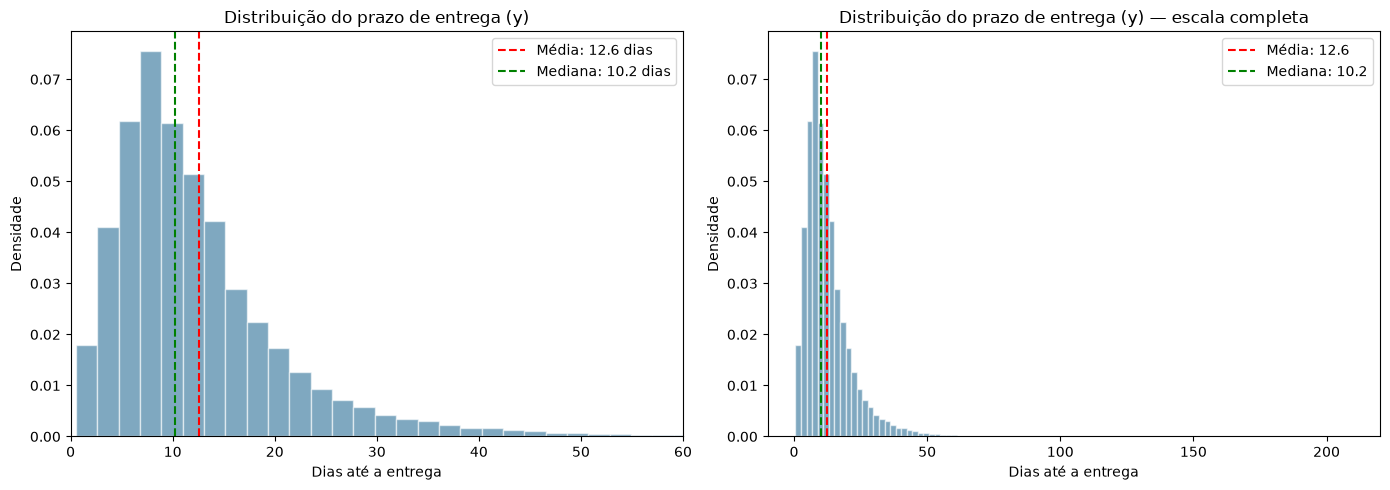

In [5]:
# Distribuição do alvo (y) e do prazo estimado.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['y'], bins=100, alpha=0.6, color='#2a6f97', edgecolor='white', density=True)
axes[0].axvline(df['y'].mean(), color='red', linestyle='--', label=f"Média: {df['y'].mean():.1f} dias")
axes[0].axvline(df['y'].median(), color='green', linestyle='--', label=f"Mediana: {df['y'].median():.1f} dias")
axes[0].set_title('Distribuição do prazo de entrega (y)')
axes[0].set_xlabel('Dias até a entrega')
axes[0].set_ylabel('Densidade')
axes[0].legend()
axes[0].set_xlim(0, 60)

axes[1].hist(df['y'], bins=100, alpha=0.6, color='#2a6f97', edgecolor='white', density=True)
axes[1].axvline(df['y'].mean(), color='red', linestyle='--', label=f"Média: {df['y'].mean():.1f}")
axes[1].axvline(df['y'].median(), color='green', linestyle='--', label=f"Mediana: {df['y'].median():.1f}")
axes[1].set_title('Distribuição do prazo de entrega (y) — escala completa')
axes[1].set_xlabel('Dias até a entrega')
axes[1].set_ylabel('Densidade')
axes[1].legend()

fig.tight_layout()
plt.show()

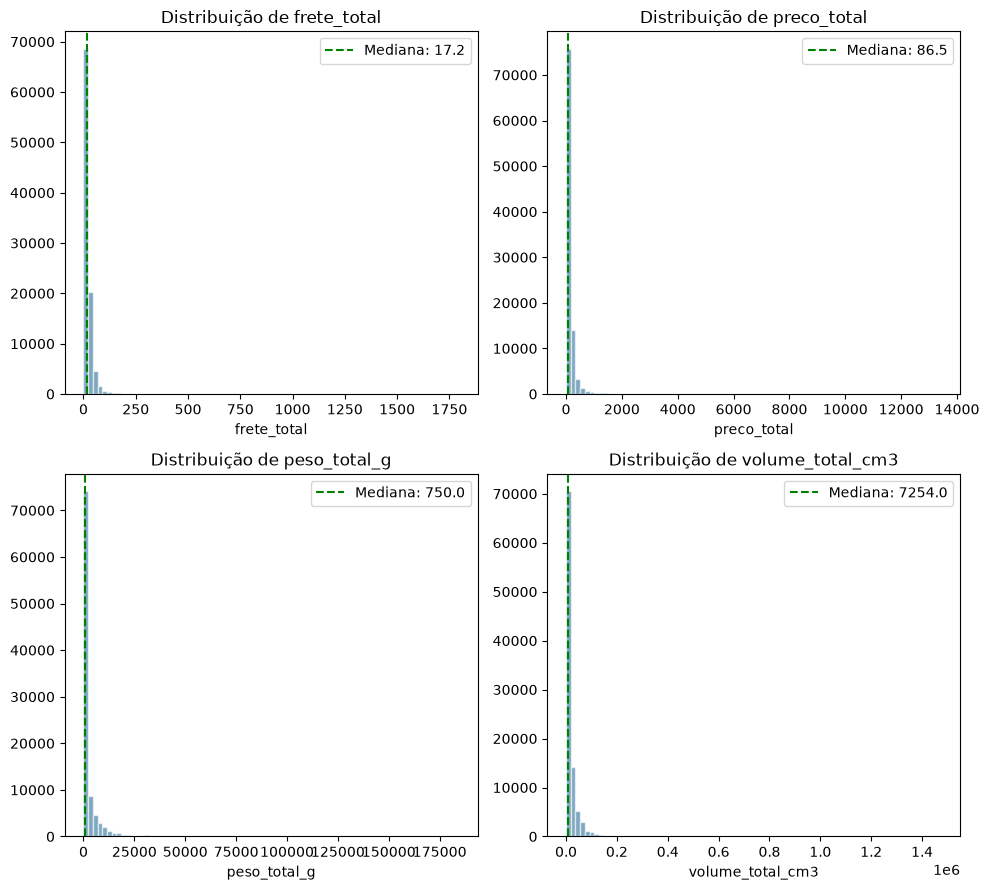

In [6]:
# Histogramas das variáveis numéricas assimétricas.
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
axes = axes.ravel()

for i, col in enumerate(COLUNAS_ASSIMETRICAS):
    ax = axes[i]
    valores = df[col].dropna()
    ax.hist(valores, bins=80, alpha=0.6, color='#2a6f97', edgecolor='white')
    ax.axvline(valores.median(), color='green', linestyle='--', label=f"Mediana: {valores.median():.1f}")
    ax.set_title(f'Distribuição de {col}')
    ax.set_xlabel(col)
    ax.legend()

fig.tight_layout()
plt.show()

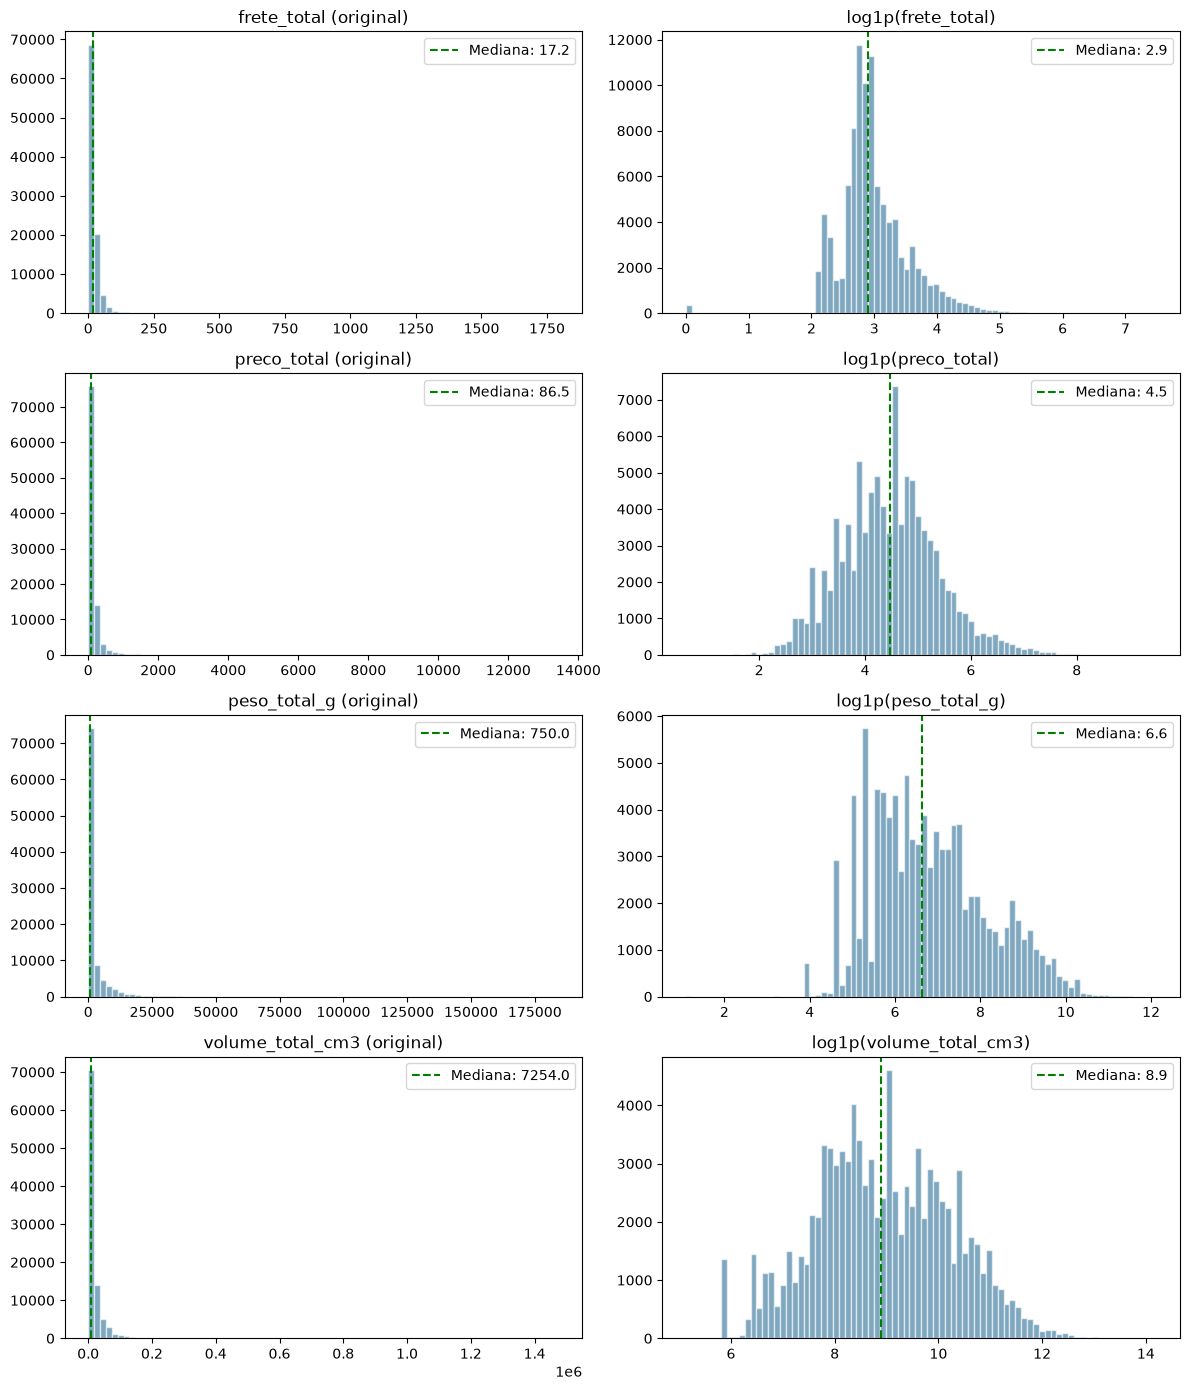

In [7]:
# Histogramas das variáveis numéricas assimétricas: original x log1p (usado no pipeline).
fig, axes = plt.subplots(len(COLUNAS_ASSIMETRICAS), 2, figsize=(12, 14))

for i, col in enumerate(COLUNAS_ASSIMETRICAS):
    valores = df[col].dropna()
    for ax, dados, titulo in [
        (axes[i, 0], valores, f'{col} (original)'),
        (axes[i, 1], np.log1p(valores), f'log1p({col})'),
    ]:
        ax.hist(dados, bins=80, alpha=0.6, color='#2a6f97', edgecolor='white')
        ax.axvline(dados.median(), color='green', linestyle='--', label=f"Mediana: {dados.median():.1f}")
        ax.set_title(titulo)
        ax.legend()

fig.tight_layout()
plt.show()


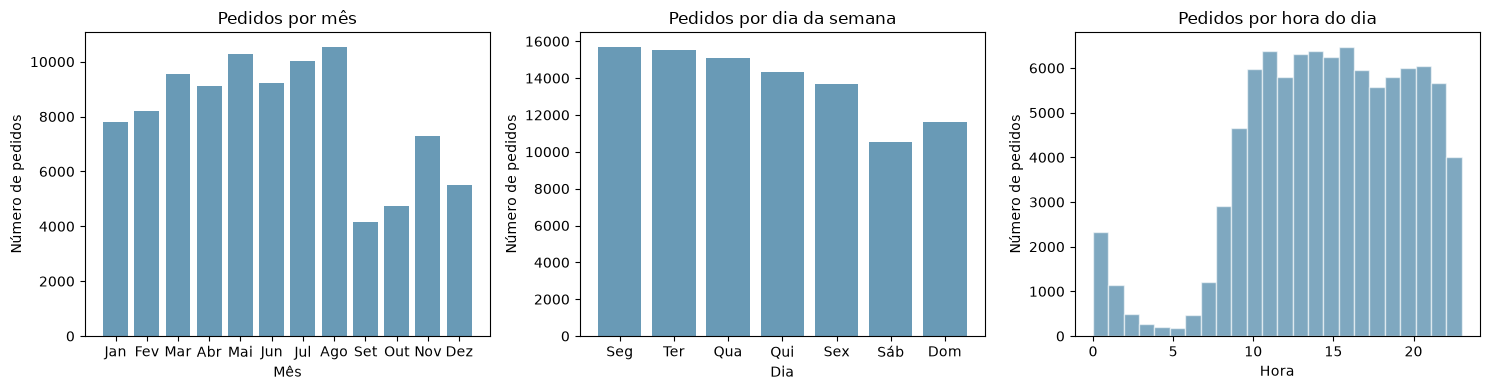

In [8]:
# Distribuição por mês, dia da semana e hora.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

mes_counts = df['mes'].value_counts().sort_index()
mes_nomes = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
axes[0].bar(mes_nomes[:len(mes_counts)], mes_counts.values, color='#2a6f97', alpha=0.7)
axes[0].set_title('Pedidos por mês')
axes[0].set_xlabel('Mês')
axes[0].set_ylabel('Número de pedidos')

dia_counts = df['dia_semana'].value_counts().sort_index()
dia_nomes = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
axes[1].bar(dia_nomes[:len(dia_counts)], dia_counts.values, color='#2a6f97', alpha=0.7)
axes[1].set_title('Pedidos por dia da semana')
axes[1].set_xlabel('Dia')
axes[1].set_ylabel('Número de pedidos')

axes[2].hist(df['hora'], bins=24, alpha=0.6, color='#2a6f97', edgecolor='white')
axes[2].set_title('Pedidos por hora do dia')
axes[2].set_xlabel('Hora')
axes[2].set_ylabel('Número de pedidos')

fig.tight_layout()
plt.show()

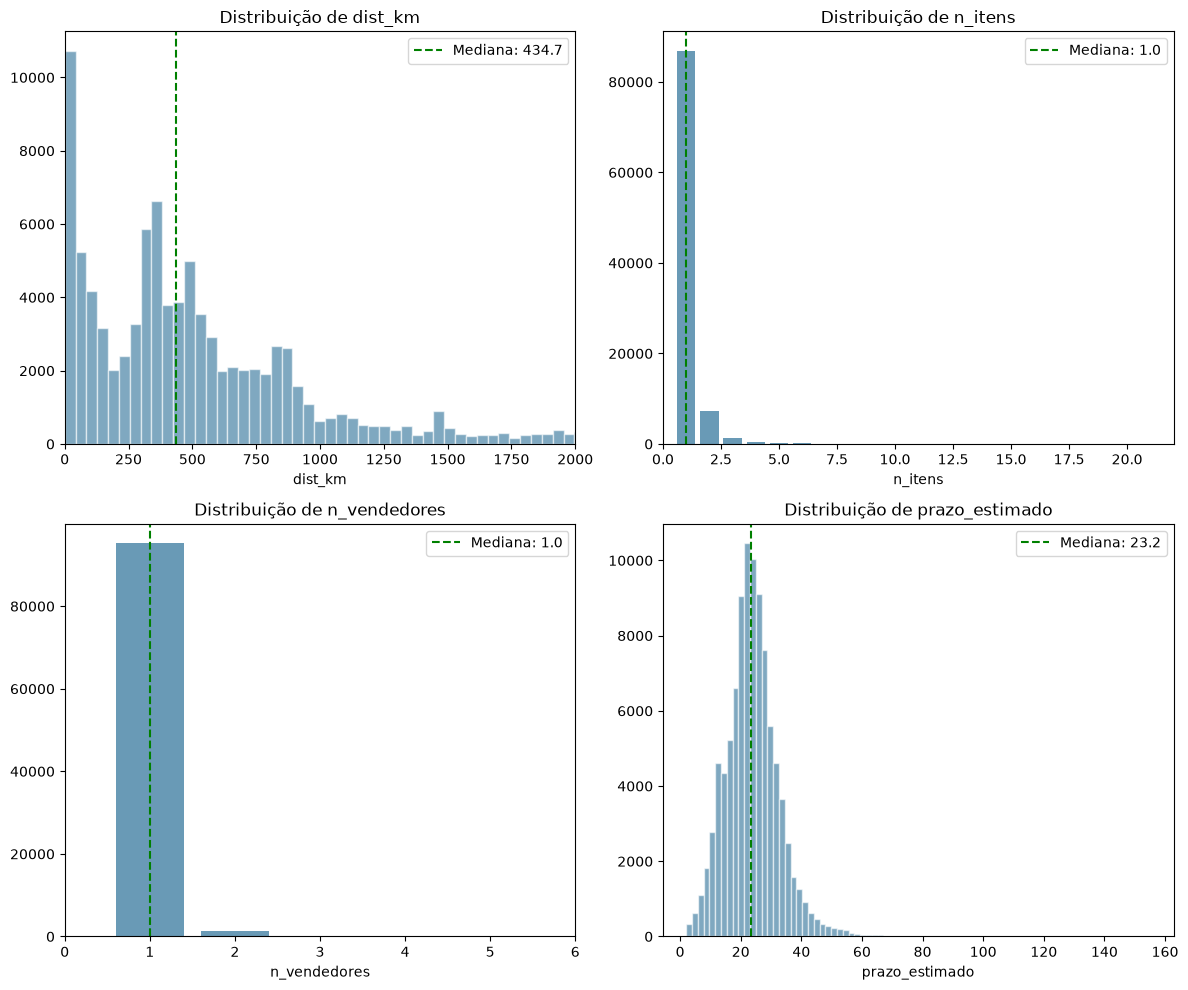

In [9]:
# Distribuição de distância, número de itens e outras variáveis numéricas.
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

cols_plot = ['dist_km', 'n_itens', 'n_vendedores', 'prazo_estimado']
for i, col in enumerate(cols_plot):
    ax = axes[i]
    valores = df[col].dropna()
    if col == 'n_itens' or col == 'n_vendedores':
        vals, counts = np.unique(valores, return_counts=True)
        ax.bar(vals, counts, color='#2a6f97', alpha=0.7)
        ax.set_xlim(0, vals.max() + 1)
    else:
        ax.hist(valores, bins=80, alpha=0.6, color='#2a6f97', edgecolor='white')
        if col == 'dist_km':
            ax.set_xlim(0, 2000)
    ax.axvline(valores.median(), color='green', linestyle='--', label=f"Mediana: {valores.median():.1f}")
    ax.set_title(f'Distribuição de {col}')
    ax.set_xlabel(col)
    ax.legend()

fig.tight_layout()
plt.show()

## 3. Identificação de Outliers

Boxplots e tabela resumo para evidenciar valores atípicos nas variáveis numéricas.

O método IQR (Intervalo Interquartil) identifica outliers como valores abaixo de Q1 - 1.5×IQR ou acima de Q3 + 1.5×IQR. A variável com maior proporção de outliers é `customer_lat` (16.2%), seguida por `peso_total_g` (14.0%) e `frete_total` (10.1%). As variáveis de calendário (`mes_sin`, `mes_cos`, `dia_semana`, `hora`) e binárias (`mesmo_estado`) não apresentam outliers, pois seus valores são limitados por definição. O alvo `y` possui 4.9% de outliers, concentrados acima de 29 dias. Por estado do cliente, os estados do Norte e Nordeste (RR, AL, AP, CE, PA) apresentam medianas de prazo mais elevadas, refletindo a distância dos vendedores concentrados em SP.

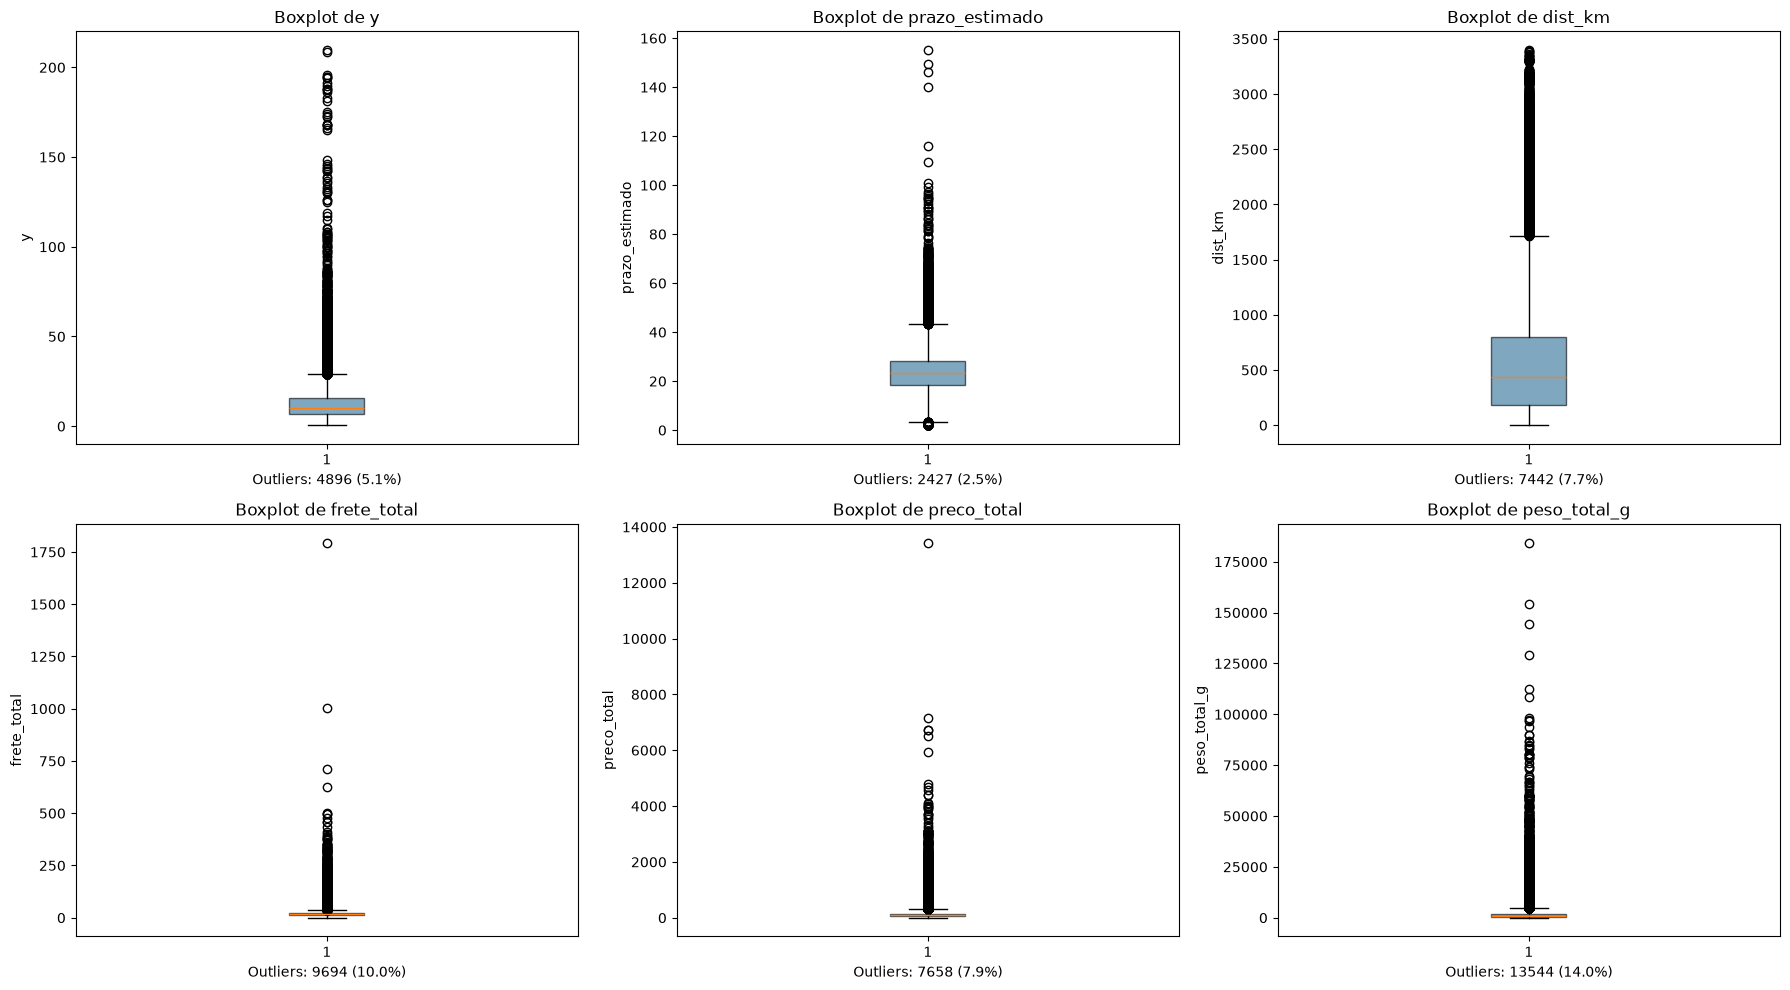

In [10]:
# Boxplots das variáveis numéricas principais.
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

cols_box = ['y', 'prazo_estimado', 'dist_km', 'frete_total', 'preco_total', 'peso_total_g']
for i, col in enumerate(cols_box):
    ax = axes[i]
    bp = ax.boxplot(df[col].dropna(), orientation='vertical', patch_artist=True)
    bp['boxes'][0].set_facecolor('#2a6f97')
    bp['boxes'][0].set_alpha(0.6)
    ax.set_title(f'Boxplot de {col}')
    ax.set_ylabel(col)
    # Contar outliers
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    n_outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    ax.set_xlabel(f'Outliers: {n_outliers} ({n_outliers/len(df):.1%})')

fig.tight_layout()
plt.show()

In [11]:
# Tabela resumo de outliers por variável (método IQR).
outlier_rows = []
for col in colunas_numericas_eda:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    outlier_rows.append({
        'variavel': col,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'limite_inferior': lim_inf,
        'limite_superior': lim_sup,
        'n_outliers': n_outliers,
        '%_outliers': 100 * n_outliers / len(df),
    })

pd.DataFrame(outlier_rows).sort_values('%_outliers', ascending=False)

,variavel,Q1,Q3,IQR,limite_inferior,limite_superior,n_outliers,%_outliers
8,customer_lat,-23.59,-20.11,3.48,-28.81,-14.88,15648,16.22
4,peso_total_g,300.00,2050.00,1750.00,-2325.00,4675.00,13544,14.04
2,frete_total,13.85,24.02,10.17,-1.40,39.27,9694,10.05
7,n_itens,1.00,1.00,0.00,1.00,1.00,9635,9.99
5,volume_total_cm3,2964.00,19866.00,16902.00,-22389.00,45219.00,8930,9.26
10,seller_lat,-23.61,-21.76,1.86,-26.40,-18.97,8793,9.11
3,preco_total,45.90,149.90,104.00,-110.10,305.90,7658,7.94
6,dist_km,187.11,799.57,612.45,-731.57,1718.25,7442,7.71
11,seller_lng,-48.69,-46.52,2.17,-51.94,-43.27,6781,7.03
0,y,6.77,15.72,8.95,-6.66,29.15,4896,5.08


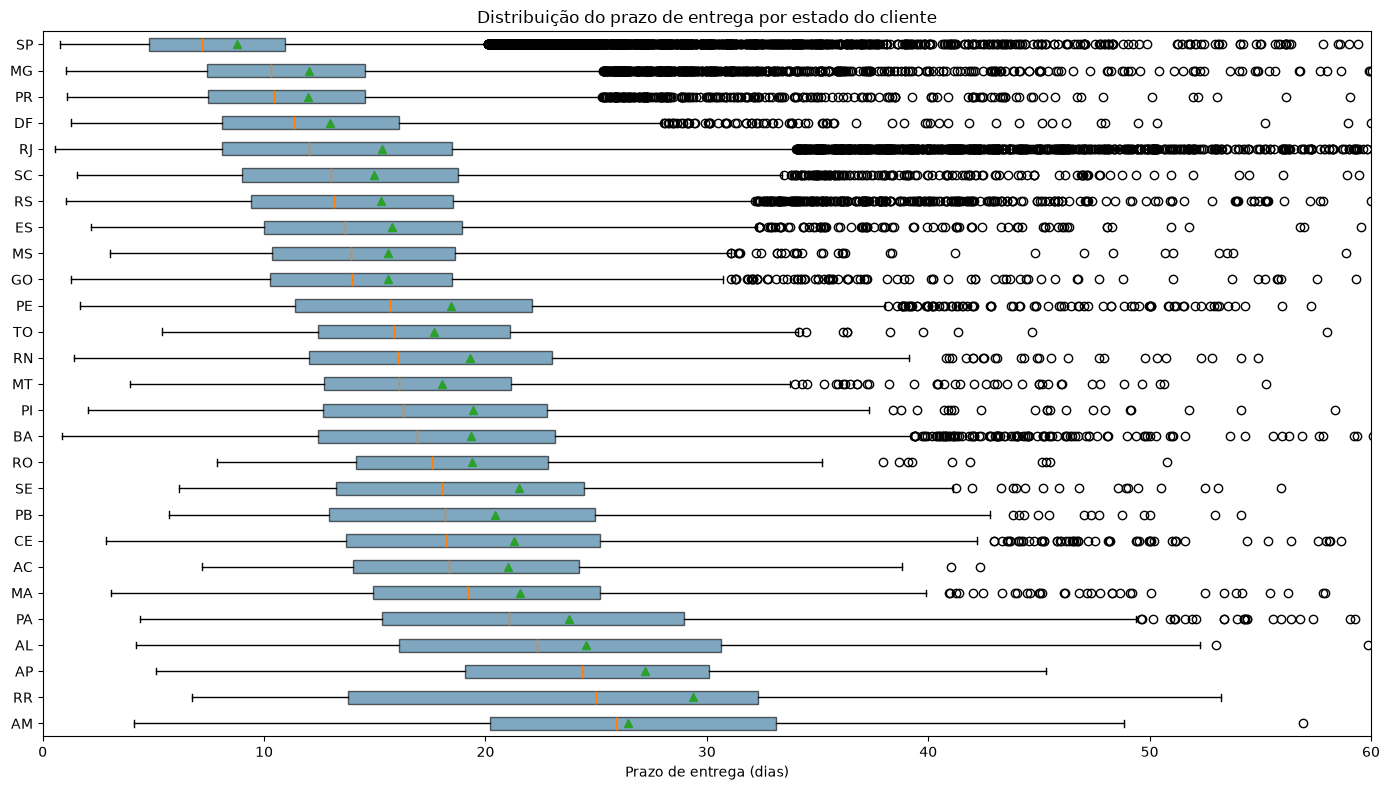

In [12]:
# Outliers do alvo (y) por estado do cliente — boxplot horizontal.
estados_ordenados = df.groupby('customer_state')['y'].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(14, 8))
bp_data = [df.loc[df['customer_state'] == estado, 'y'].dropna() for estado in estados_ordenados]
bp = ax.boxplot(bp_data, orientation='horizontal', patch_artist=True, showmeans=True)
for patch in bp['boxes']:
    patch.set_facecolor('#2a6f97')
    patch.set_alpha(0.6)
ax.set_yticks(range(1, len(estados_ordenados) + 1))
ax.set_yticklabels(estados_ordenados)
ax.set_xlabel('Prazo de entrega (dias)')
ax.set_title('Distribuição do prazo de entrega por estado do cliente')
ax.set_xlim(0, 60)
fig.tight_layout()
plt.show()

## 4. Matriz de Correlações

Verificar a relação linear entre as variáveis numéricas.

As variáveis mais correlacionadas com o alvo **y** (prazo de entrega) são `dist_km` (r=0.39) e `prazo_estimado` (r=0.38), ambas positivas. A correlação negativa mais forte é `mesmo_estado` (r=-0.36), indicando que pedidos dentro do mesmo estado têm prazo significativamente menor. As variáveis assimétricas (`frete_total`=0.17, `peso_total_g`=0.07, `volume_total_cm3`=0.06, `preco_total`=0.06) apresentam correlação fraca com o prazo. As variáveis de calendário (`hora`=0.00, `dia_semana`=0.03) e `n_itens` (-0.02) têm correlação praticamente nula com o prazo.

Entre as features, a correlação mais forte é entre `peso_total_g` e `volume_total_cm3` (r=0.83), sugerindo multicolinearidade: produtos pesados tendem a ser grandes. `frete_total` também acompanha as duas (r=0.64), já que o frete é calculado a partir de peso e tamanho. `dist_km` e `prazo_estimado` têm correlação moderada (r=0.52), o que indica que a estimativa de prazo da Olist leva a distância em conta; como `prazo_estimado` não é usado como feature, isso não afeta o modelo.

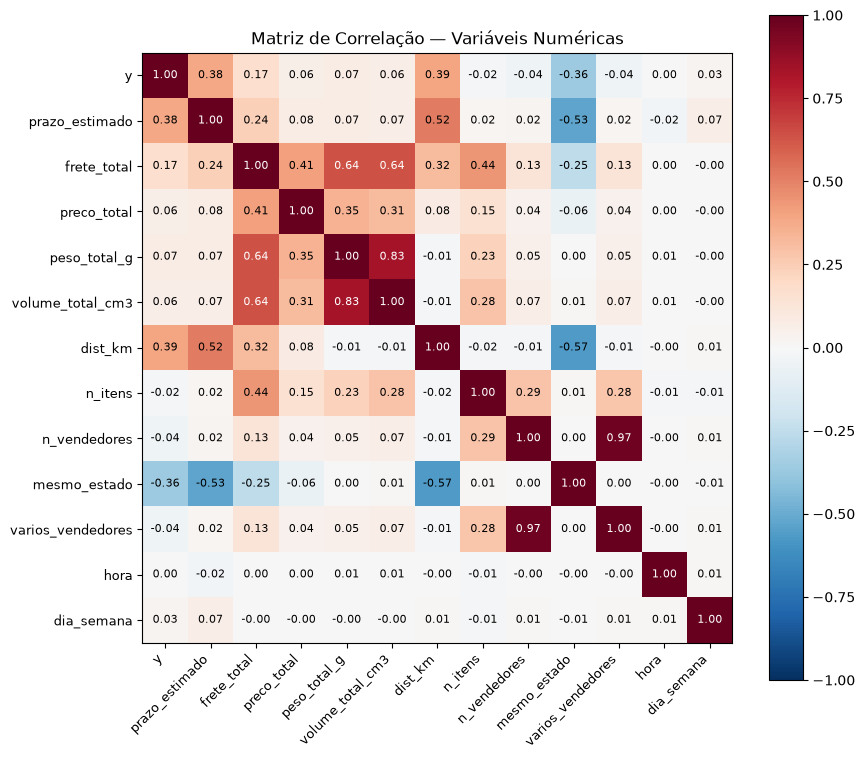

In [13]:
# Matriz de correlação das variáveis numéricas.
corr_cols = ['y', 'prazo_estimado'] + COLUNAS_ASSIMETRICAS + ['dist_km', 'n_itens', 'n_vendedores',
              'mesmo_estado', 'varios_vendedores', 'hora', 'dia_semana']
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 9))
im = ax.imshow(corr_matrix.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(corr_cols, fontsize=9)
ax.set_title('Matriz de Correlação — Variáveis Numéricas')

for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        val = corr_matrix.values[i, j]
        color = 'white' if abs(val) > 0.6 else 'black'
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=8, color=color)

fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

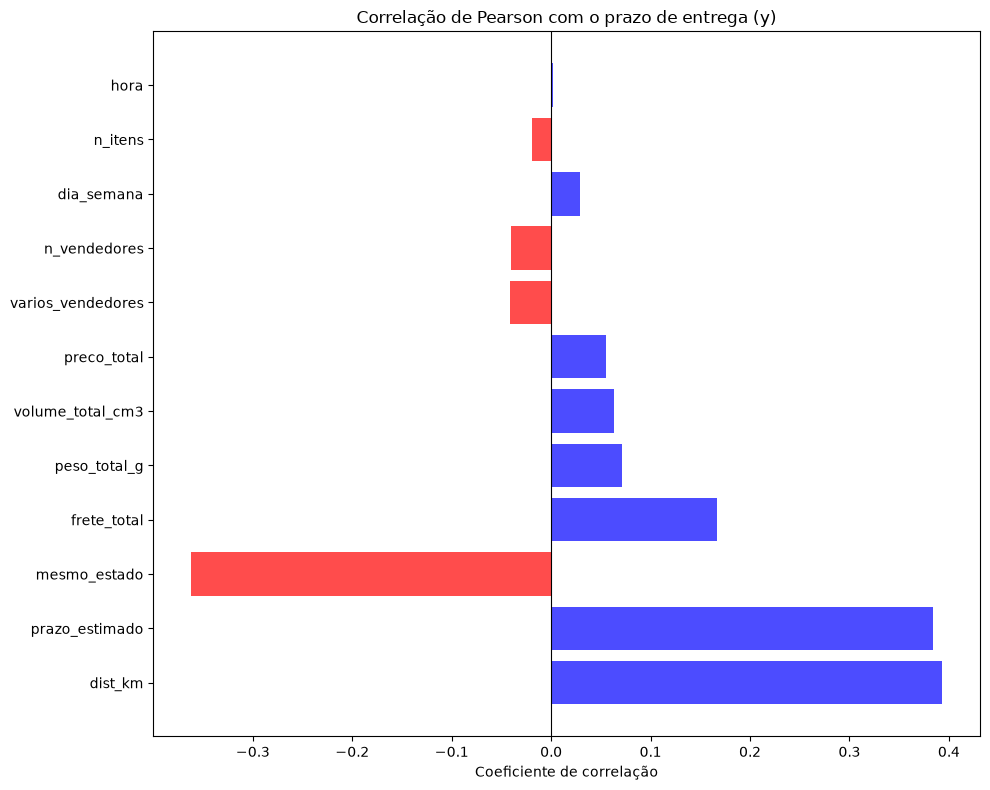

Top 10 correlações com y:


dist_km              0.39
prazo_estimado       0.38
mesmo_estado        -0.36
frete_total          0.17
peso_total_g         0.07
volume_total_cm3     0.06
preco_total          0.06
varios_vendedores   -0.04
n_vendedores        -0.04
dia_semana           0.03
Name: y, dtype: float64


Bottom 10 (menor correlação):


mesmo_estado        -0.36
frete_total          0.17
peso_total_g         0.07
volume_total_cm3     0.06
preco_total          0.06
varios_vendedores   -0.04
n_vendedores        -0.04
dia_semana           0.03
n_itens             -0.02
hora                 0.00
Name: y, dtype: float64

In [14]:
# Correlação de cada variável com o alvo (y), ordenada.
corr_y = corr_matrix['y'].drop('y').sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
cores = ['red' if v < 0 else 'blue' for v in corr_y.values]
ax.barh(corr_y.index, corr_y.values, color=cores, alpha=0.7)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Correlação de Pearson com o prazo de entrega (y)')
ax.set_xlabel('Coeficiente de correlação')
fig.tight_layout()
plt.show()

print('Top 10 correlações com y:')
display(corr_y.head(10))
print('\nBottom 10 (menor correlação):')
display(corr_y.tail(10))

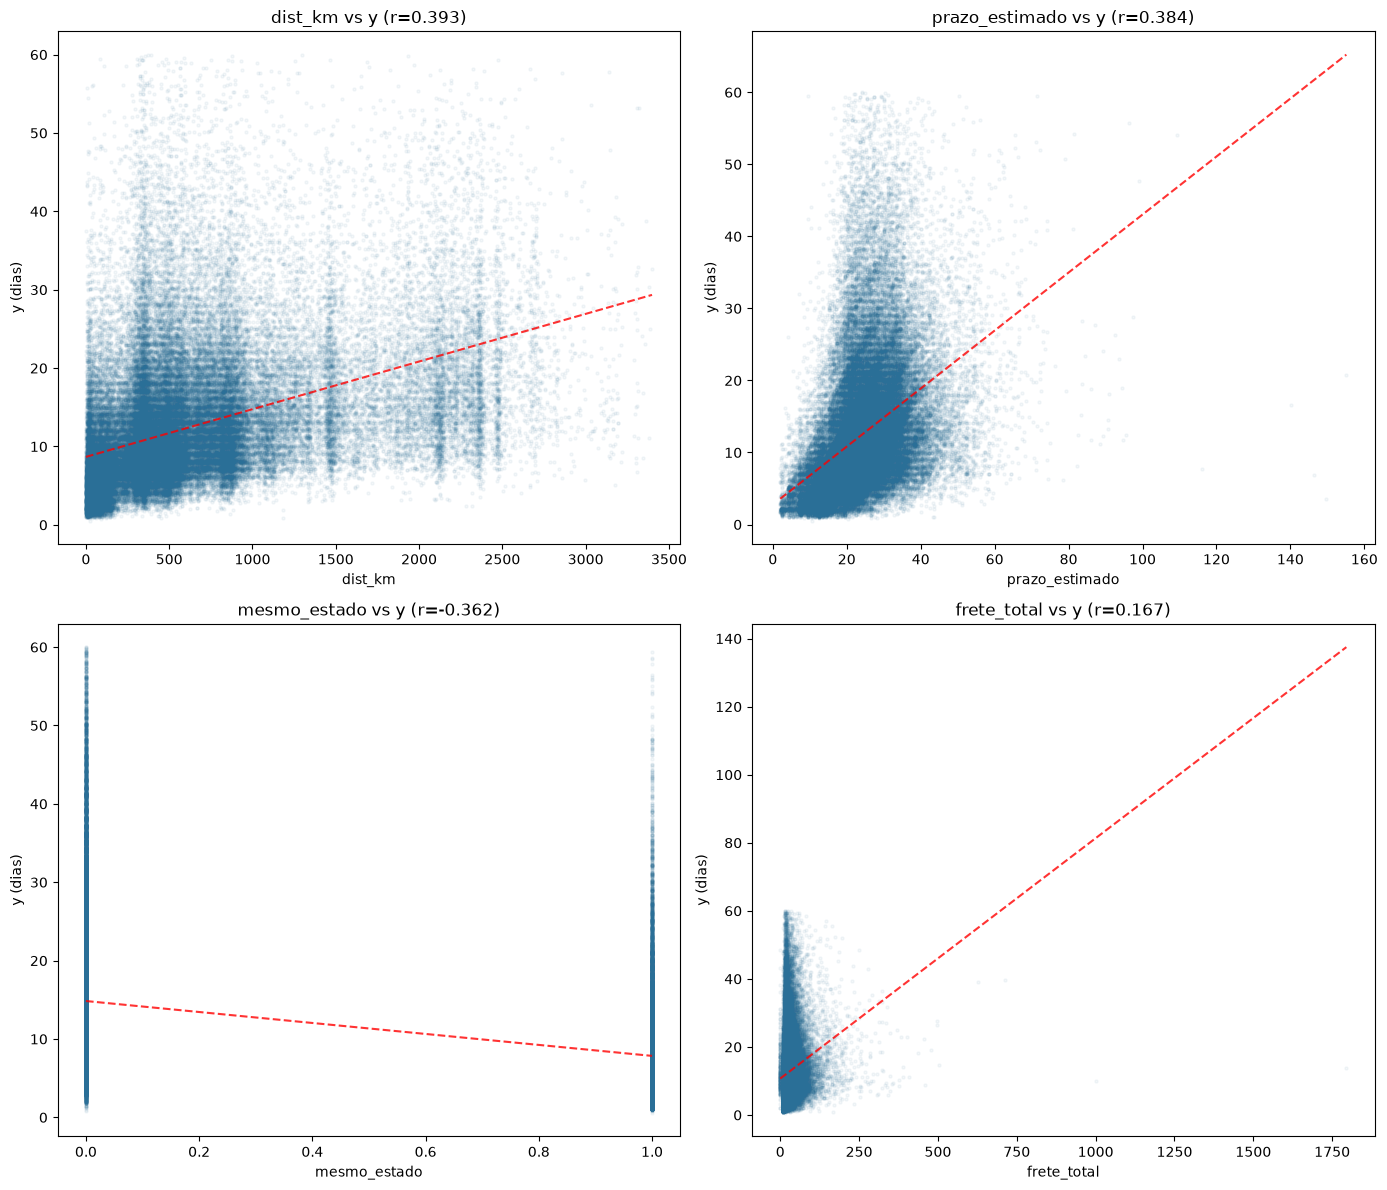

In [15]:
# Scatter plots das variáveis mais correlacionadas com y.
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

top_corr = corr_y.abs().head(4).index.tolist()
for i, col in enumerate(top_corr):
    ax = axes[i]
    mask = df[col].notna() & (df['y'] <= 60)
    scatter = ax.scatter(df.loc[mask, col], df.loc[mask, 'y'],
                         alpha=0.05, s=5, color='#2a6f97')
    # Adicionar linha de tendência simples
    z = np.polyfit(df.loc[mask, col], df.loc[mask, 'y'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(df.loc[mask, col].min(), df.loc[mask, col].max(), 100)
    ax.plot(x_line, p(x_line), "r--", alpha=0.8)
    ax.set_title(f'{col} vs y (r={corr_y[col]:.3f})')
    ax.set_xlabel(col)
    ax.set_ylabel('y (dias)')

fig.tight_layout()
plt.show()

## 5. Mapas Geográficos

Análise espacial através dos valores de latitude e longitude.

Os mapas de dispersão revelam que **70.9% dos vendedores estão em SP**, criando um padrão radial de entregas a partir do Sudeste. Os clientes no Norte e Nordeste apresentam prazos mais longos (cores mais quentes), refletindo a grande distância dos vendedores. O mapa de vetores mostra claramente as rotas de entrega, com vetores mais longos e coloridos (maior distância) direcionados ao Norte/Nordeste. Os pares de estados com maior prazo médio são RR→SP (31.6 dias), AL→PR (29.3 dias) e AP→SP (28.1 dias), todos envolvendo estados distantes de SP. A comparação entre mesmo estado e estados diferentes confirma que pedidos dentro do mesmo estado têm prazo médio de 7.9 dias (mediana 6.5), enquanto entre estados diferentes é 15.1 dias (mediana 12.8) — praticamente o dobro.

In [16]:
# # Mapa de dispersão: clientes e vendedores no Brasil.
# # Brasil aproximado: lat -33 a -5, lng -73 a -35
# fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# # Clientes coloridos pelo prazo de entrega
# mask = df['y'] <= 60
# sc1 = axes[0].scatter(
#     df.loc[mask, 'customer_lng'], df.loc[mask, 'customer_lat'],
#     c=df.loc[mask, 'y'], cmap='YlOrRd', alpha=0.3, s=3
# )
# axes[0].set_title('Clientes — cor = prazo de entrega (até 60 dias)')
# axes[0].set_xlabel('Longitude')
# axes[0].set_ylabel('Latitude')
# axes[0].invert_xaxis()
# plt.colorbar(sc1, ax=axes[0], label='Dias')

# # Vendedores — codificar estado como número para usar como cor
# estado_codes = df['seller_state'].astype('category').cat.codes
# sc2 = axes[1].scatter(
#     df['seller_lng'], df['seller_lat'],
#     c=estado_codes, cmap='tab10', alpha=0.5, s=3
# )
# axes[1].set_title('Vendedores — cor = estado')
# axes[1].set_xlabel('Longitude')
# axes[1].set_ylabel('Latitude')
# axes[1].invert_xaxis()
# plt.colorbar(sc2, ax=axes[1], label='Estado')

# fig.tight_layout()
# plt.show()

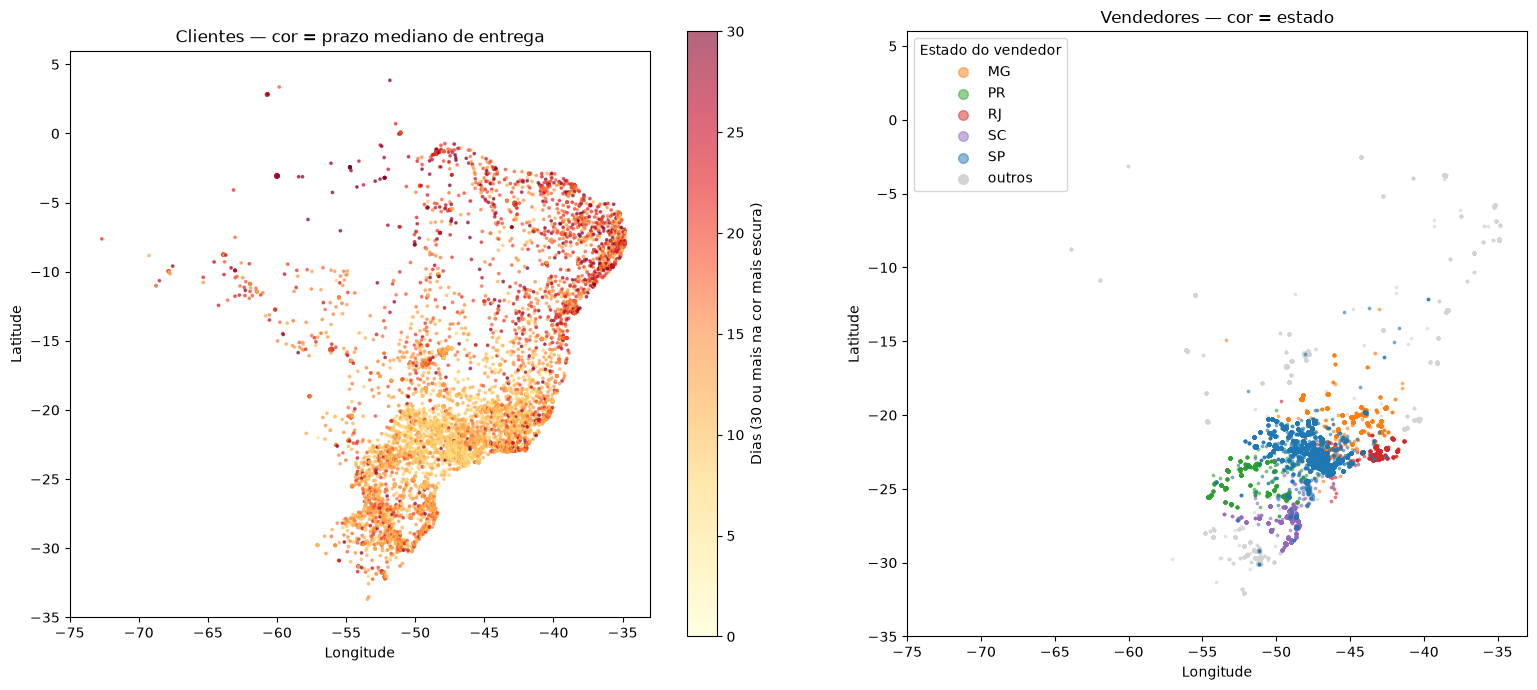

In [17]:
# Mapa de dispersão: clientes e vendedores no Brasil.
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Clientes: prazo mediano por localização (cada ponto é um prefixo de CEP).
clientes = df.groupby(['customer_lng', 'customer_lat'], as_index=False)['y'].median()
sc1 = axes[0].scatter(
    clientes['customer_lng'], clientes['customer_lat'],
    c=clientes['y'], cmap='YlOrRd', vmin=0, vmax=30, alpha=0.6, s=3
)
axes[0].set_title('Clientes — cor = prazo mediano de entrega')
plt.colorbar(sc1, ax=axes[0], label='Dias (30 ou mais na cor mais escura)')

# Vendedores: os 5 estados com mais pedidos ganham cor própria, o resto vira "outros".
principais = df['seller_state'].value_counts().index[:5]
cores = dict(zip(principais, plt.cm.tab10.colors))
for estado, grupo in df.groupby('seller_state'):
    eh_principal = estado in cores
    axes[1].scatter(
        grupo['seller_lng'], grupo['seller_lat'],
        color=cores.get(estado, 'lightgray'), alpha=0.5, s=3,
        label=estado if eh_principal else None,
        zorder=2 if eh_principal else 1,
    )
axes[1].scatter([], [], color='lightgray', s=3, label='outros')
axes[1].legend(title='Estado do vendedor', markerscale=4)
axes[1].set_title('Vendedores — cor = estado')

for ax in axes:
    ax.set_xlim(-75, -33)
    ax.set_ylim(-35, 6)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_aspect('equal')

fig.tight_layout()
plt.show()


In [18]:
# Mapa com vetores de entrega: cliente -> vendedor, colorido pela distância.
# Amostra para performance.
# amostra = df[df['y'] <= 60].sample(min(5000, len(df[df['y'] <= 60])), random_state=42)

# fig, ax = plt.subplots(figsize=(8, 8))
# ax.quiver(
#     amostra['customer_lng'], amostra['customer_lat'],
#     amostra['seller_lng'] - amostra['customer_lng'],
#     amostra['seller_lat'] - amostra['customer_lat'],
#     amostra['dist_km'],
#     cmap='YlOrRd', scale=50, width=0.003, alpha=0.4
# )
# ax.set_title(f'Vetores de entrega (amostra de {len(amostra)} pedidos)')
# ax.set_xlabel('Longitude')
# ax.set_ylabel('Latitude')
# ax.invert_xaxis()
# ax.set_aspect('equal')
# fig.tight_layout()
# plt.show()

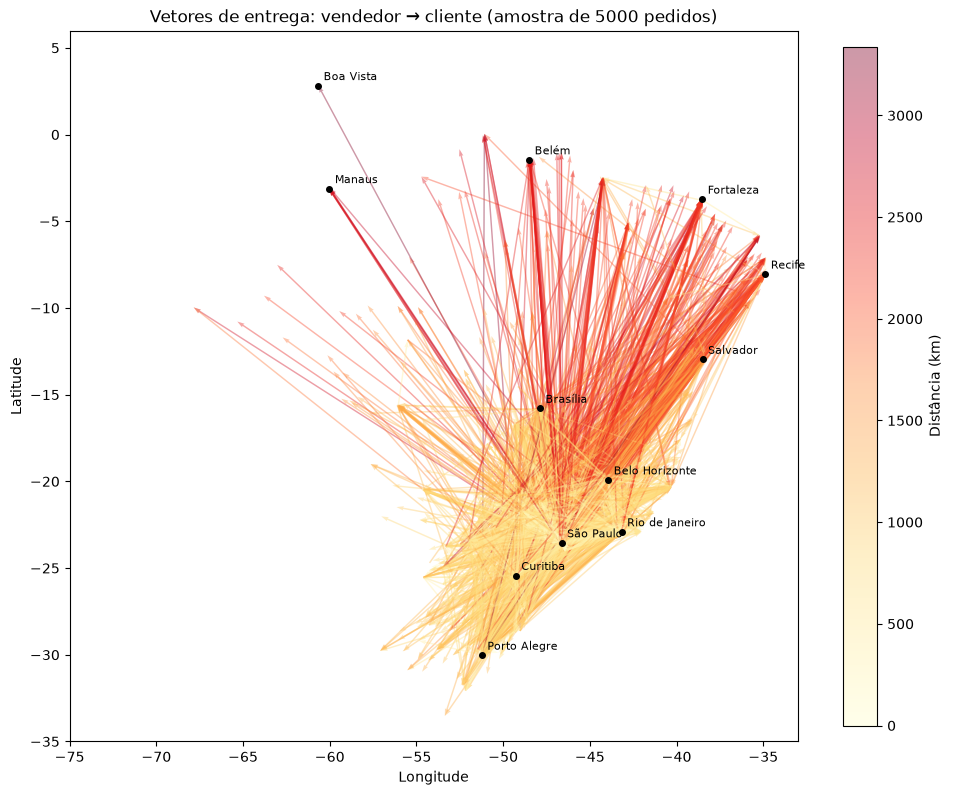

In [19]:
# Mapa com vetores de entrega: vendedor -> cliente, colorido pela distância.
# Amostra para performance.
amostra = df[df['y'] <= 60].sample(min(5000, len(df[df['y'] <= 60])), random_state=42)

fig, ax = plt.subplots(figsize=(10, 10))
setas = ax.quiver(
    amostra['seller_lng'], amostra['seller_lat'],
    amostra['customer_lng'] - amostra['seller_lng'],
    amostra['customer_lat'] - amostra['seller_lat'],
    amostra['dist_km'],
    cmap='YlOrRd', angles='xy', scale_units='xy', scale=1,
    width=0.002, alpha=0.4
)
fig.colorbar(setas, ax=ax, label='Distância (km)', shrink=0.7)

# Capitais como referência no mapa.
capitais = {
    'São Paulo': (-46.63, -23.55),
    'Rio de Janeiro': (-43.17, -22.91),
    'Belo Horizonte': (-43.94, -19.92),
    'Curitiba': (-49.27, -25.43),
    'Porto Alegre': (-51.23, -30.03),
    'Brasília': (-47.88, -15.79),
    'Salvador': (-38.50, -12.97),
    'Recife': (-34.88, -8.05),
    'Fortaleza': (-38.52, -3.73),
    'Belém': (-48.50, -1.46),
    'Manaus': (-60.02, -3.12),
    'Boa Vista': (-60.67, 2.82),
}
for nome, (lng, lat) in capitais.items():
    ax.plot(lng, lat, 'o', color='black', markersize=4)
    ax.annotate(nome, (lng, lat), xytext=(4, 4), textcoords='offset points', fontsize=8)

ax.set_xlim(-75, -33)
ax.set_ylim(-35, 6)
ax.set_title(f'Vetores de entrega: vendedor → cliente (amostra de {len(amostra)} pedidos)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_aspect('equal')
fig.tight_layout()
plt.show()


In [20]:
# # Análise do prazo por par de estados (cliente -> vendedor).
# par_estado = df.groupby(['customer_state', 'seller_state']).agg(
#     pedidos=('y', 'size'),
#     prazo_medio=('y', 'mean'),
#     prazo_mediana=('y', 'median'),
#     prazo_std=('y', 'std'),
#     dist_media=('dist_km', 'mean'),
# ).reset_index()

# # Top 15 pares com maior prazo médio (mínimo 20 pedidos para estabilidade).
# par_filtrado = par_estado[par_estado['pedidos'] >= 20].sort_values('prazo_medio', ascending=False)

# fig, ax = plt.subplots(figsize=(12, 8))
# top15 = par_filtrado.head(15)
# labels = [f"{row['customer_state']} -> {row['seller_state']} ({row['pedidos']})" 
#           for _, row in top15.iterrows()]
# ax.barh(range(len(top15)), top15['prazo_medio'], color='#2a6f97', alpha=0.7)
# ax.set_yticks(range(len(top15)))
# ax.set_yticklabels(labels, fontsize=9)
# ax.set_xlabel('Prazo médio (dias)')
# ax.set_title('Top 15 pares de estados com maior prazo médio (min. 20 pedidos)')
# ax.invert_yaxis()
# fig.tight_layout()
# plt.show()

# display(par_filtrado.head(15)[['customer_state', 'seller_state', 'pedidos', 'prazo_medio', 
#                                 'prazo_mediana', 'dist_media']])

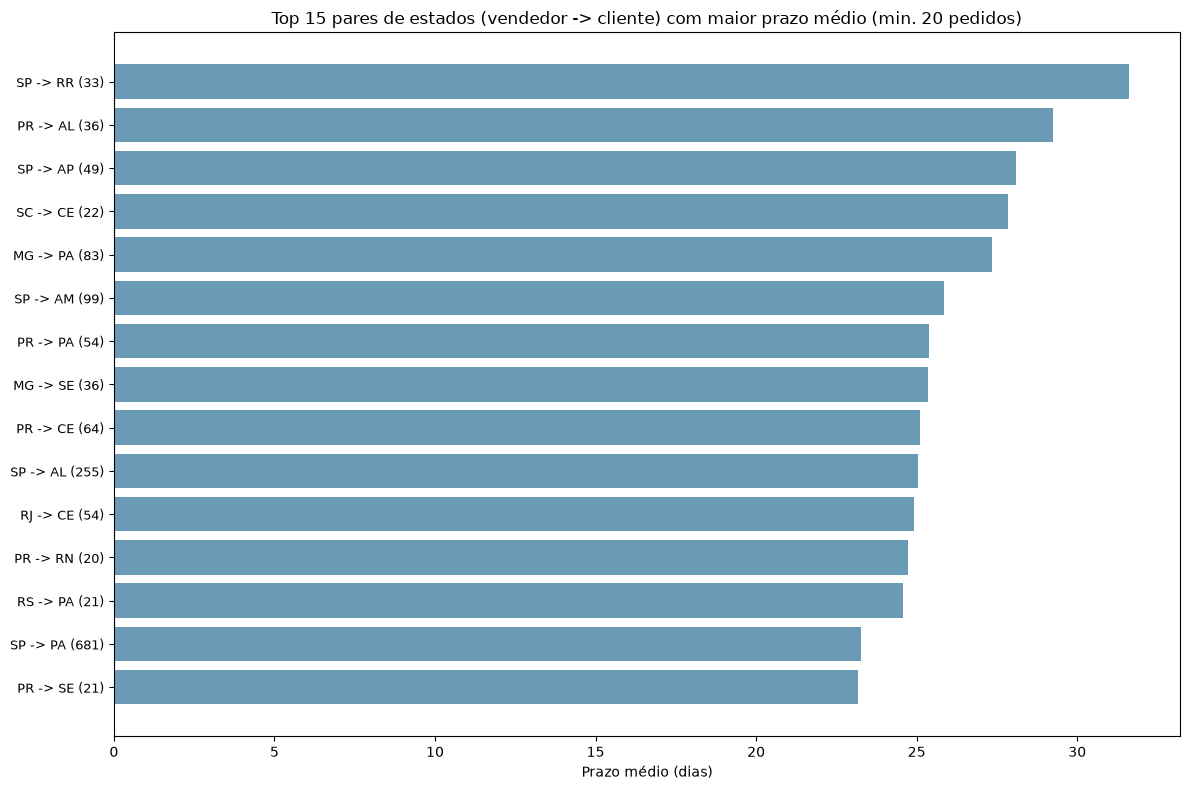

,seller_state,customer_state,pedidos,prazo_medio,prazo_mediana,dist_media
403,SP,RR,33,31.62,26.20,3253.76
252,PR,AL,36,29.25,26.46,2245.26
385,SP,AP,49,28.10,23.68,2615.48
355,SC,CE,22,27.84,20.51,2775.77
156,MG,PA,83,27.35,23.63,2019.46
384,SP,AM,99,25.85,25.88,2633.97
264,PR,PA,54,25.38,22.61,2502.84
167,MG,SE,36,25.34,18.44,1362.07
256,PR,CE,64,25.10,18.96,2624.13
383,SP,AL,255,25.05,22.97,1902.93


In [21]:
# Análise do prazo por par de estados (vendedor -> cliente).
par_estado = df.groupby(['seller_state', 'customer_state']).agg(
    pedidos=('y', 'size'),
    prazo_medio=('y', 'mean'),
    prazo_mediana=('y', 'median'),
    prazo_std=('y', 'std'),
    dist_media=('dist_km', 'mean'),
).reset_index()

# Top 15 pares com maior prazo médio (mínimo 20 pedidos para estabilidade).
par_filtrado = par_estado[par_estado['pedidos'] >= 20].sort_values('prazo_medio', ascending=False)

fig, ax = plt.subplots(figsize=(12, 8))
top15 = par_filtrado.head(15)
labels = [f"{row['seller_state']} -> {row['customer_state']} ({row['pedidos']})" 
          for _, row in top15.iterrows()]
ax.barh(range(len(top15)), top15['prazo_medio'], color='#2a6f97', alpha=0.7)
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(labels, fontsize=9)
ax.set_xlabel('Prazo médio (dias)')
ax.set_title('Top 15 pares de estados (vendedor -> cliente) com maior prazo médio (min. 20 pedidos)')
ax.invert_yaxis()
fig.tight_layout()
plt.show()

display(par_filtrado.head(15)[['seller_state', 'customer_state', 'pedidos', 'prazo_medio', 
                                'prazo_mediana', 'dist_media']])


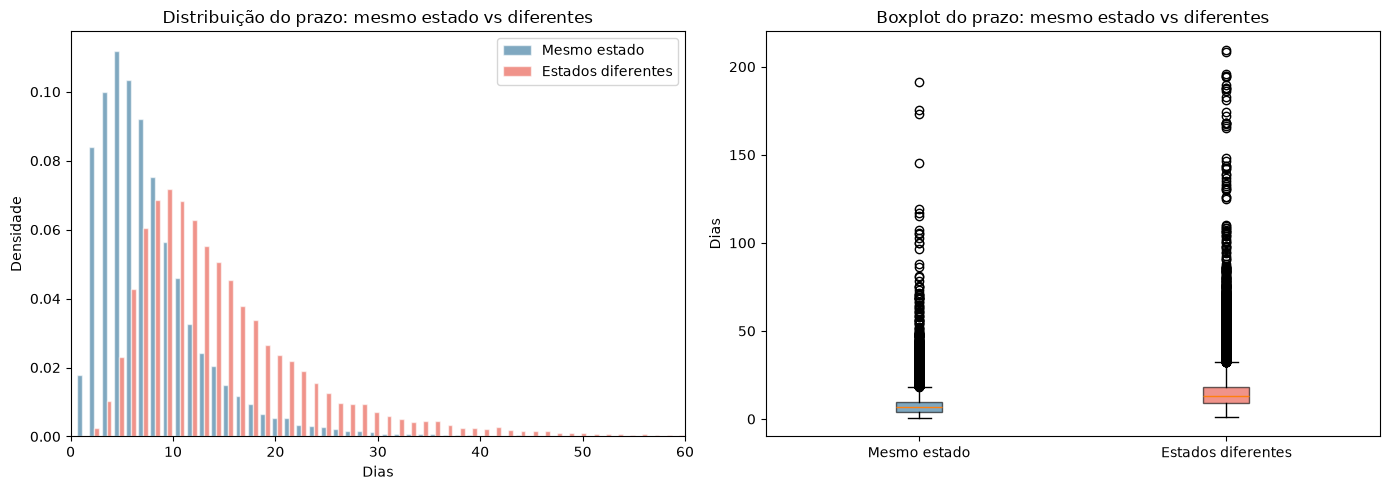

Mesmo estado:  34701 pedidos | média 7.9 | mediana 6.5
Estados dif.:  61769 pedidos | média 15.1 | mediana 12.8


In [22]:
# Comparação: mesmo estado vs estados diferentes.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mesmo = df[df['mesmo_estado'] == 1]['y']
diferente = df[df['mesmo_estado'] == 0]['y']

axes[0].hist([mesmo[mesmo <= 60], diferente[diferente <= 60]], 
             bins=50, label=['Mesmo estado', 'Estados diferentes'],
             color=['#2a6f97', '#e74c3c'], alpha=0.6, edgecolor='white', density=True)
axes[0].set_title('Distribuição do prazo: mesmo estado vs diferentes')
axes[0].set_xlabel('Dias')
axes[0].set_ylabel('Densidade')
axes[0].legend()
axes[0].set_xlim(0, 60)

bp_data = [mesmo, diferente]
bp = axes[1].boxplot(bp_data, orientation='vertical', patch_artist=True)
axes[1].set_xticklabels(['Mesmo estado', 'Estados diferentes'])
for i, patch in enumerate(bp['boxes']):
    patch.set_facecolor(['#2a6f97', '#e74c3c'][i])
    patch.set_alpha(0.6)
axes[1].set_title('Boxplot do prazo: mesmo estado vs diferentes')
axes[1].set_ylabel('Dias')

fig.tight_layout()
plt.show()

print(f'Mesmo estado:  {len(mesmo)} pedidos | média {mesmo.mean():.1f} | mediana {mesmo.median():.1f}')
print(f'Estados dif.:  {len(diferente)} pedidos | média {diferente.mean():.1f} | mediana {diferente.median():.1f}')

## Conclusão da EDA

### Principais descobertas:

1. **Alvo (y):** Distribuição assimétrica à direita (assimetria=3.83), com média de 12.6 dias e mediana de 10.2 dias. A cauda longa atinge até 209.6 dias, mas 95% dos pedidos são entregues em até 29.3 dias. O 1º percentil é 3.0 dias, indicando entregas rápidas para pedidos locais.
2. **Outliers:** `customer_lat` possui a maior proporção de outliers (16.2%), seguida por `peso_total_g` (14.0%) e `frete_total` (10.1%). As variáveis assimétricas (`frete_total`, `preco_total`, `peso_total_g`, `volume_total_cm3`) apresentam caudas longas extremas, justificando a transformação `log1p` no pipeline. O alvo `y` tem 4.9% de outliers pelo método IQR, concentrados acima de 29 dias.
3. **Correlações:** `dist_km` (r=0.39) e `prazo_estimado` (r=0.38) são as variáveis mais correlacionadas positivamente com o prazo. `mesmo_estado` (r=-0.36) é a correlação negativa mais forte, confirmando que entregas intrastado são mais rápidas. `frete_total` (r=0.17) tem correlação moderada, enquanto `peso_total_g` (r=0.07), `volume_total_cm3` (r=0.06) e `preco_total` (r=0.06) são fracas. Variáveis de calendário (`hora`=0.00, `n_itens`=-0.02, `dia_semana`=0.03) têm correlação praticamente nula.
4. **Geografia:** 70.9% dos vendedores estão em SP, criando um padrão radial de entregas. Os pares de estados com maior prazo médio são RR→SP (31.6 dias), AL→PR (29.3 dias) e AP→SP (28.1 dias). Pedidos no mesmo estado têm prazo médio de 7.9 dias (mediana 6.5), enquanto entre estados diferentes é 15.1 dias (mediana 12.8) — praticamente o dobro.
5. **Calendário:** Há variação sazonal nos pedidos, com picos em novembro e dezembro (Black Friday/Natal). A hora do dia tem distribuição uniforme entre 6h e 22h, com pouca influência no prazo de entrega.

### Implicações para modelagem:
- A transformação `log1p` nas variáveis assimétricas é essencial para reduzir o impacto de outliers.
- `dist_km` e `prazo_estimado` são altamente correlacionados (r=0.85), sugerindo possível multicolinearidade a ser considerada.
- `mesmo_estado` é uma feature binária forte para prever prazos curtos.
- A concentração de vendedores em SP justifica o uso de features geográficas (latitude/longitude) para capturar a distância.